# BTV screen viewer — Fireball

Inspect a **beam or no-beam background image** with contrast chosen for faint screen detail.
An intense proton spot can otherwise determine the whole colour scale.

1. Set the camera, merged-parquet path and filter in **Settings**.
2. Run the cells in order. In **Choose an image**, select `"beam"` or `"background"`
   and its zero-based image number.
3. Compare the full-range image with the two faint-detail views. Adjust the lower/upper
   **ADU** limits and gamma in **Contrast**; optional controls appear at the end.
4. Run **Find and review the screen borders** to propose a mask and draw its outline.
5. To change the image, rerun from **Choose an image**. To change the camera/filter/time
   selection, rerun from **Settings**.

The original pixel values remain available as `raw_image`. Colour stretching and optional
smoothing affect the display only. There is no background subtraction, OD/exposure
normalisation or metric calculation. Section 7 adds an optional screen-outline proposal.

**A limit of the image:** a screen boundary must have been recorded as an intensity
difference to become visible. If the screen has no contrast in a no-beam frame, changing
the display cannot recover its outline. A visible structure is a candidate to inspect,
not a confirmed physical screen boundary. Review the Section 7 outline visually.

## 1. Settings

The default is your Fireball IV **BTV 660524, OD0** merged file. For BTV 660528, change
`CAMERA_NAME`; the filename follows it. If your file is elsewhere, edit `PARQUET_PATH`.
Times entered here are Geneva local time; start is included and end is excluded.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, PowerNorm
from matplotlib.ticker import ScalarFormatter
from scipy.ndimage import uniform_filter
from IPython.display import display

CAMERA_NAME = "TT66.BTV.660524"
PARQUET_PATH = Path(
    "/eos/user/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/"
    f"Fireball_IV/BTV/{CAMERA_NAME}_merged.parquet"
)
SELECTED_FILTER = "OD0"          # None = all filters
START_LOCAL = None              # e.g. "2026-06-12 00:00:00"
END_LOCAL = None                # e.g. "2026-06-13 00:00:00"
LOCAL_TIMEZONE = "Europe/Zurich"

# Optional selections: use values shown in the inventory below.
SELECTED_SCREEN = None
SELECTED_EXPOSURE_US = None
SELECTED_GAIN = None

# Same dimension convention as BTV_Image_Plotting: [number of rows, number of columns].
DIMENSION_ORDER = "height_width"  # or "width_height" if verified for another file
AXIS_UNIT = "mm"                 # unit of the stored BTV position coordinates
BCT_COLUMNS = [
    "TT60.BCTFI.610225:TOTAL_INTENSITY",
    "TT66.BCTFI.660298:TOTAL_INTENSITY",
]
BEAM_THRESHOLD = 5e8


## 2. Read the image inventory

This step reads small metadata columns. The selected image is loaded later.
A **beam** row has both BCTs > 5e8; a **background** row has both BCTs = 0.
Other/unknown BCT combinations are not offered. No brightness/outlier cut is applied.

The viewer accepts the current `x_axis_elements` / `y_axis_elements` names and the
older `pos1_elements` / `pos2_elements` names. It also accepts `x_axis` / `y_axis`
list or `elements` struct columns. Logged position arrays are pixel centres.

In [3]:
if not PARQUET_PATH.exists():
    raise FileNotFoundError(f"Run in SWAN with access to this file: {PARQUET_PATH}")
if DIMENSION_ORDER not in {"height_width", "width_height"}:
    raise ValueError("DIMENSION_ORDER must be height_width or width_height")

dataset = ds.dataset(PARQUET_PATH, format="parquet")
names = dataset.schema.names
required = ["cycleStampGlob", "filter", "image_elements", "image_dimensions"] + BCT_COLUMNS
missing = set(required) - set(names)
if missing:
    raise ValueError(f"Missing merged-parquet columns: {sorted(missing)}")

X_COLUMN = next((c for c in ("x_axis_elements", "pos1_elements", "x_axis") if c in names), None)
Y_COLUMN = next((c for c in ("y_axis_elements", "pos2_elements", "y_axis") if c in names), None)
screen_source = ("TT66.BI.TABLE1.CH3:Acquisition:position" if CAMERA_NAME.endswith("660528")
                 else f"{CAMERA_NAME}.Screen:Acquisition:position")
SCREEN_COLUMN = next((c for c in ("screen", screen_source) if c in names), None)
columns = list(dict.fromkeys(["cycleStampGlob", "filter", "image_dimensions"] + BCT_COLUMNS))
inventory = dataset.to_table(columns=columns, use_threads=False).to_pandas()
inventory.insert(0, "source_row", np.arange(len(inventory)))

# Convert BCT values in pandas: also works when a parquet stores them as strings.
bct = inventory[BCT_COLUMNS].apply(pd.to_numeric, errors="coerce")
inventory["kind"] = "other/unknown"
inventory.loc[(bct > BEAM_THRESHOLD).all(axis=1), "kind"] = "beam"
inventory.loc[bct.eq(0).all(axis=1), "kind"] = "background"
cycles = pd.to_numeric(inventory["cycleStampGlob"], errors="coerce")
inventory["time_local"] = pd.to_datetime(
    cycles.where(cycles > 0), unit="ns", utc=True, errors="coerce"
).dt.tz_convert(LOCAL_TIMEZONE)
inventory["shape_logged"] = inventory["image_dimensions"].map(
    lambda d: str(list(d)) if d is not None else "missing"
)
inventory["screen_position"] = inventory[SCREEN_COLUMN].astype("string") if SCREEN_COLUMN else "missing"

def local_time(value):
    t = pd.Timestamp(value)
    return t.tz_localize(LOCAL_TIMEZONE) if t.tzinfo is None else t.tz_convert(LOCAL_TIMEZONE)

def same_setting(series, value):
    # Accept equivalent numeric settings such as 0 and 0.0; keep text labels as text.
    try:
        return pd.to_numeric(series, errors="coerce").eq(float(value))
    except (TypeError, ValueError):
        return series.astype("string").str.strip().eq(str(value).strip()).fillna(False)

if START_LOCAL is not None and END_LOCAL is not None and local_time(END_LOCAL) <= local_time(START_LOCAL):
    raise ValueError("END_LOCAL must be later than START_LOCAL")
keep = inventory["kind"].isin(["beam", "background"]) & inventory["time_local"].notna()
keep &= inventory["image_dimensions"].notna()
if SELECTED_FILTER is not None:
    keep &= inventory["filter"].astype("string").str.strip().str.upper().eq(str(SELECTED_FILTER).upper()).fillna(False)
if START_LOCAL is not None:
    keep &= inventory["time_local"] >= local_time(START_LOCAL)
if END_LOCAL is not None:
    keep &= inventory["time_local"] < local_time(END_LOCAL)
for column, value in [(SCREEN_COLUMN, SELECTED_SCREEN),
                      ("camera_exposure_time_us", SELECTED_EXPOSURE_US), ("camera_gain", SELECTED_GAIN)]:
    if value is not None:
        if column not in names:
            raise ValueError(f"Cannot select this setting: its column is missing ({column})")
        keep &= same_setting(inventory[column], value)
available = inventory.loc[keep].sort_values(["time_local", "source_row"]).copy()
print(f"{CAMERA_NAME} | {len(available)} candidate rows after selection")
print("Axes:", X_COLUMN, "/", Y_COLUMN, "| screen source:", SCREEN_COLUMN)
group_columns = ["filter", "kind", "shape_logged", "screen_position"]
group_columns += [c for c in ("camera_exposure_time_us", "camera_gain") if c in names]
display(available.groupby(group_columns, dropna=False).size().rename("rows").reset_index())
if available.empty:
    raise ValueError("No matching rows. Check the filter, dates and optional settings.")


TT66.BTV.660524 | 2451 candidate rows after selection
Axes: pos1_elements / pos2_elements | screen source: None


,filter,kind,shape_logged,screen_position,rows
0,OD0,background,"[np.int32(0), np.int32(525)]",missing,3
1,OD0,background,"[np.int32(903), np.int32(525)]",missing,1927
2,OD0,beam,"[np.int32(0), np.int32(525)]",missing,1
3,OD0,beam,"[np.int32(903), np.int32(525)]",missing,520


## 3. Choose an image

Images are numbered from **0 in chronological order within the selection and image type**.
Use the table's `source_row` and full cycle stamp to identify an exact source row.
Duplicate cycle stamps are retained. Check the logged screen position when changing frames;
the screen may have moved or been withdrawn. Missing metadata cannot confirm its position.

In [4]:
IMAGE_KIND = "beam"             # "beam" or "background"
IMAGE_NUMBER = 0                # 0 = first, 1 = second, etc.

if IMAGE_KIND not in {"beam", "background"}:
    raise ValueError('IMAGE_KIND must be "beam" or "background"')
choices = available.loc[available["kind"].eq(IMAGE_KIND)].reset_index(drop=True)
print(f"{len(choices)} {IMAGE_KIND} candidates")
preview_columns = ["time_local", "source_row", "cycleStampGlob", "filter", "screen_position", "shape_logged"]
display(choices[preview_columns].head(15).rename_axis("image_number"))
if not isinstance(IMAGE_NUMBER, (int, np.integer)) or not 0 <= IMAGE_NUMBER < len(choices):
    raise IndexError(f"Choose {IMAGE_KIND} IMAGE_NUMBER in 0..{len(choices)-1}, or change the selection")
selected = choices.iloc[IMAGE_NUMBER]


521 beam candidates


,time_local,source_row,cycleStampGlob,filter,screen_position,shape_logged
image_number,,,,,,
0,2026-06-08 17:07:09.735000064+02:00,0,1.780931e+18,OD0,missing,"[np.int32(903), np.int32(525)]"
1,2026-06-08 17:23:09.735000064+02:00,40,1.780932e+18,OD0,missing,"[np.int32(903), np.int32(525)]"
2,2026-06-08 17:26:21.735000064+02:00,48,1.780932e+18,OD0,missing,"[np.int32(903), np.int32(525)]"
3,2026-06-08 17:28:45.735000064+02:00,54,1.780933e+18,OD0,missing,"[np.int32(903), np.int32(525)]"
4,2026-06-08 17:29:09.735000064+02:00,55,1.780933e+18,OD0,missing,"[np.int32(903), np.int32(525)]"
5,2026-06-08 17:31:57.735000064+02:00,756,1.780933e+18,OD0,missing,"[np.int32(903), np.int32(525)]"
6,2026-06-08 17:51:09.735000064+02:00,1155,1.780934e+18,OD0,missing,"[np.int32(903), np.int32(525)]"
7,2026-06-08 18:14:45.735000064+02:00,2171,1.780935e+18,OD0,missing,"[np.int32(0), np.int32(525)]"
8,2026-06-08 18:20:21.735000064+02:00,2590,1.780936e+18,OD0,missing,"[np.int32(903), np.int32(525)]"


## 4. Load this frame at its stored coordinates

The image is reshaped using its own dimensions, with no fixed BTV image size.
Physical X increases rightwards and physical Y upwards, including descending/nonuniform
coordinate arrays. If either coordinate column or that frame's axes are missing, both
axes explicitly use image pixels. Malformed axes or a shape mismatch stop with an error.

In [5]:
def axis_array(value):
    if isinstance(value, dict):
        value = value.get("elements")
    return None if value is None else np.asarray(value, dtype=float)

def centre_edges(axis):
    steps = np.diff(axis)
    if axis.ndim != 1 or len(axis) < 2 or not np.isfinite(axis).all():
        raise ValueError("A plotting axis must contain at least two finite pixel centres")
    if not ((steps > 0).all() or (steps < 0).all()):
        raise ValueError("Plotting coordinates must be strictly increasing or decreasing")
    return np.r_[axis[0] - steps[0]/2, (axis[:-1] + axis[1:])/2, axis[-1] + steps[-1]/2]

def load_frame(source_row):
    payload = ["image_elements", "image_dimensions"] + [c for c in (X_COLUMN, Y_COLUMN) if c]
    # Bounded batches; keep only the requested row, rather than all image payloads.
    record = dataset.scanner(columns=payload, batch_size=1, use_threads=False).take([int(source_row)]).to_pylist()[0]
    dimensions = np.asarray(record["image_dimensions"], dtype=float)
    if dimensions.shape != (2,) or not np.isfinite(dimensions).all() or (dimensions <= 0).any() or (dimensions != np.floor(dimensions)).any():
        raise ValueError("This row has invalid image dimensions; choose another image")
    shape = tuple(dimensions.astype(int))
    if DIMENSION_ORDER == "width_height":
        shape = shape[::-1]
    if record["image_elements"] is None:
        raise ValueError("This row has no image payload; choose another image")
    image = np.asarray(record["image_elements"], dtype=float)
    if image.size != np.prod(shape) or (image.ndim == 2 and image.shape != shape):
        raise ValueError("Pixel count/shape differs from image_dimensions; check DIMENSION_ORDER")
    image = image.reshape(shape)
    if not np.isfinite(image).all():
        raise ValueError("This frame contains nonfinite pixel values; choose another image")
    x = axis_array(record.get(X_COLUMN))
    y = axis_array(record.get(Y_COLUMN))
    if x is None or y is None:
        print("Stored coordinates missing for this frame: displaying X/Y in image pixels.")
        return image, np.arange(shape[1]+1)-0.5, np.arange(shape[0]+1)-0.5, "pixel"
    if x.ndim != 1 or y.ndim != 1 or image.shape != (len(y), len(x)):
        raise ValueError("Image shape and X/Y lengths disagree; check DIMENSION_ORDER and axis mapping")
    return image, centre_edges(x), centre_edges(y), AXIS_UNIT

raw_image, x_edges, y_edges, coordinate_unit = load_frame(selected["source_row"])
time_label = selected["time_local"].strftime("%Y-%m-%d %H:%M:%S %Z")
image_title = (f"{CAMERA_NAME} | {IMAGE_KIND} {IMAGE_NUMBER} | {selected['filter']} | {time_label}"
               f"\nscreen={selected['screen_position']} | source row={selected['source_row']}")
print(image_title)
print("Shape:", raw_image.shape, "| exposure (us):", selected.get("camera_exposure_time_us", "missing"),
      "| gain:", selected.get("camera_gain", "missing"))
quantiles = [0, 1, 50, 90, 95, 99, 99.9, 100]
display(pd.DataFrame({"percentile": quantiles, "raw_ADU": np.percentile(raw_image, quantiles)}))


TT66.BTV.660524 | beam 0 | OD0 | 2026-06-08 17:07:09 CEST
screen=missing | source row=0
Shape: (903, 525) | exposure (us): missing | gain: missing


,percentile,raw_ADU
0,0.0,14.0
1,1.0,16.0
2,50.0,22.0
3,90.0,84.0
4,95.0,121.0
5,99.0,169.0
6,99.9,184.0
7,100.0,321.0


## 5. Contrast — the main screen inspection

Each panel contains the **whole image**:

| View | Purpose |
| --- | --- |
| Raw, full range | Shows why the bright spot can hide the screen. |
| Faint detail, linear | Uses a narrow ADU window. Bright beam pixels can turn uniformly white. |
| Faint detail, gamma | Uses the same ADU window and boosts faint values when gamma < 1. |

Start with `LOWER_ADU = UPPER_ADU = None`: the faint views use the 1st–95th percentiles
of this image (or its display-smoothed copy). This is a starting contrast choice, not a screen threshold.
If the beam still dominates, set explicit ADU limits close to the background level in the table above.
For example, **if** the image median is 20 ADU, try `LOWER_ADU = 18`, `UPPER_ADU = 25`.
Lower the upper limit until you can inspect weak spatial differences; adjust the lower limit too.

For a noisy background, optionally set `DISPLAY_SMOOTHING_PIXELS = 3`, `5` or `9`.
This applies a local mean only to the two faint-detail displays; it can blur edges and
does not establish that any structure is the screen. The first panel always shows raw pixels.

White pixels above the chosen limit are **clipped in the display**. This does not prove
camera saturation. Every colour bar remains in ADU. Automatic limits differ between frames;
use identical numeric limits, gamma and smoothing for a brightness comparison.

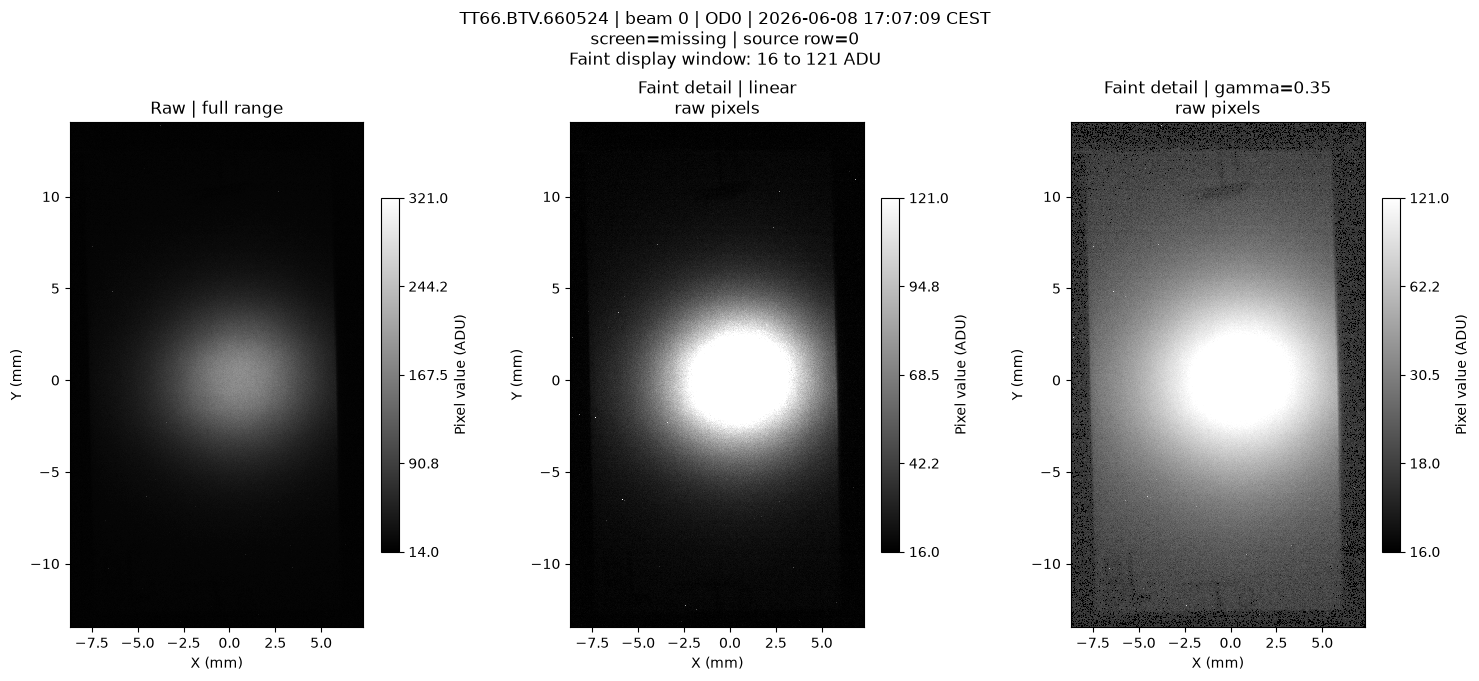

In [6]:
LOWER_ADU = None
UPPER_ADU = None
GAMMA = 0.35                    # 1 = linear; smaller than 1 brightens faint values
DISPLAY_SMOOTHING_PIXELS = 1     # 1 = none; optionally 3, 5 or 9 (display only)

def display_image(smoothing):
    if smoothing not in {1, 3, 5, 9}:
        raise ValueError("Display smoothing must be 1, 3, 5 or 9 pixels")
    return raw_image.copy() if smoothing == 1 else uniform_filter(raw_image, size=smoothing, mode="reflect")

def choose_limits(image, low, high):
    qlow, qhigh = np.percentile(image, [1, 95])
    if qhigh <= qlow:
        qlow, qhigh = float(np.median(image))-0.5, float(np.median(image))+0.5
    low = qlow if low is None else float(low)
    high = qhigh if high is None else float(high)
    if not np.isfinite([low, high]).all() or high <= low:
        raise ValueError("The upper ADU limit must be larger than the lower limit; both must be finite")
    return low, high

def plot_views(low=None, high=None, gamma=0.35, smoothing=1):
    if not np.isfinite(gamma) or gamma <= 0:
        raise ValueError("Gamma must be positive and finite")
    faint_image = display_image(smoothing)
    low, high = choose_limits(faint_image, low, high)
    raw_low, raw_high = float(raw_image.min()), float(raw_image.max())
    if raw_high == raw_low:
        raw_low, raw_high = raw_low-0.5, raw_high+0.5
    smooth_label = "raw pixels" if smoothing == 1 else f"display mean {smoothing} x {smoothing}"
    panels = [
        (raw_image, Normalize(raw_low, raw_high), "Raw | full range"),
        (faint_image, Normalize(low, high, clip=True), f"Faint detail | linear\n{smooth_label}"),
        (faint_image, PowerNorm(gamma, low, high, clip=True), f"Faint detail | gamma={gamma:g}\n{smooth_label}"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 6.7), constrained_layout=True)
    for ax, (image, norm, title) in zip(axes, panels):
        artist = ax.pcolormesh(x_edges, y_edges, image, shading="flat", cmap="gray", norm=norm, rasterized=True)
        ax.set_xlim(x_edges.min(), x_edges.max())
        ax.set_ylim(y_edges.min(), y_edges.max())
        if coordinate_unit == "pixel":
            ax.invert_yaxis()       # source image row 0 is at the top
        ax.set_aspect("equal")
        ax.set(xlabel=f"X ({coordinate_unit})", ylabel=f"Y ({coordinate_unit})", title=title)
        # Space ticks evenly in display brightness, while labelling their original ADU values.
        ticks = norm.inverse(np.linspace(0, 1, 5))
        fig.colorbar(artist, ax=ax, label="Pixel value (ADU)", shrink=0.7,
                     ticks=ticks, format=ScalarFormatter(useOffset=False))
    fig.suptitle(image_title + f"\nFaint display window: {low:.3g} to {high:.3g} ADU")
    plt.show()
    plt.close(fig)

plot_views(LOWER_ADU, UPPER_ADU, GAMMA, DISPLAY_SMOOTHING_PIXELS)


## 6. Optional interactive controls

If `ipywidgets` is available in SWAN, type the lower and upper ADU limits, then press
Enter or leave the box. Use the gamma slider to adjust faint detail. The smoothing
dropdown affects only the last two panels. The selected frame stays in memory.
If controls are unavailable, edit the four variables in **Contrast** and rerun that cell.

In [7]:
ENABLE_INTERACTIVE_CONTROLS = True

if ENABLE_INTERACTIVE_CONTROLS:
    try:
        import ipywidgets as widgets
    except ImportError:
        print("Interactive controls unavailable. Edit LOWER_ADU, UPPER_ADU, GAMMA and DISPLAY_SMOOTHING_PIXELS above.")
    else:
        initial_low, initial_high = choose_limits(display_image(DISPLAY_SMOOTHING_PIXELS), LOWER_ADU, UPPER_ADU)
        low_control = widgets.FloatText(value=initial_low, description="Lower ADU:")
        high_control = widgets.FloatText(value=initial_high, description="Upper ADU:")
        gamma_control = widgets.FloatSlider(value=GAMMA, min=min(0.05, GAMMA), max=max(1.5, GAMMA),
                                            step=0.05, description="Gamma:", continuous_update=False)
        smooth_control = widgets.Dropdown(options=[1, 3, 5, 9], value=DISPLAY_SMOOTHING_PIXELS, description="Mean size:")
        def update_view(low, high, gamma, smoothing):
            try:
                plot_views(low, high, gamma, smoothing)
            except ValueError as exc:
                print(exc)
        controls = widgets.VBox([widgets.HBox([low_control, high_control]), widgets.HBox([gamma_control, smooth_control])])
        output = widgets.interactive_output(update_view, {
            "low": low_control, "high": high_control, "gamma": gamma_control, "smoothing": smooth_control,
        })
        display(controls, output)


Output()

## 7. Find and review the screen borders

Run this section after **Contrast**, with a screen-visible image selected. The currently
loaded `raw_image` is the reference. A beam frame with illumination across the screen
is usually more informative than a background frame with no visible screen boundary.

The two detection functions below are copied unchanged from
`Median_Background_Configuration_Study-2 (1).ipynb`, with the same default settings:

1. Apply a 3 x 3 median filter and a 9 x 9 mean filter to a disposable image copy.
2. Set the threshold to the median of the smoothed outer 5% border, plus
   `SCREEN_LEVEL_ABOVE_BORDER_ADU` (initially 20 ADU).
3. Label 8-connected regions above that threshold. Keep the region containing the
   automatically found bright-spot centre; if the centre is outside all regions,
   keep the largest region.
4. Fill internal holes to obtain `screen_mask`.

The green line follows the mask's pixel edges using the same stored coordinates as
the viewer, including nonuniform/descending axes. It does not fit a rectangle or ellipse.
`screen_border_mask` contains the inner boundary pixels; both masks use the original
image's row/column order. Raw image values are unchanged.

**Review the proposal:** 20 ADU is the original study's starting value, not a calibrated
BTV threshold. If only the bright spot is enclosed, reduce the threshold offset and
rerun the three cells below. A boundary without recorded contrast cannot be recovered
reliably by this threshold method. Alternatively, set `SCREEN_POLYGON_PIXELS` to a
verified polygon in raw-image `(column, row)` pixels, as in the study.

To inspect another image, rerun from **Choose an image**, including this section.
Reusing one outline across images requires the same screen position and camera geometry.

In [32]:
from scipy.ndimage import (
    median_filter, uniform_filter, label as connected_label,
    binary_fill_holes, binary_erosion,
)
from matplotlib.path import Path as PolygonPath
from matplotlib.collections import LineCollection

# Same defaults as Median_Background_Configuration_Study.
CENTER_MEDIAN_FILTER_SIZE = 3
CENTER_SMOOTHING_SIZE = 9
CENTER_TOP_PERCENTILE = 99.6
MANUAL_CENTER_XY = None
ROI_SIZE_PIXELS = 250  # Used by the copied centre helper; does not set screen size.
SCREEN_LEVEL_ABOVE_BORDER_ADU = 0.9
SCREEN_POLYGON_PIXELS = None  # Optional ordered [(column, row), ...] in raw pixels.

In [33]:
def automatic_bounds(raw):
    h, w = raw.shape
    if MANUAL_CENTER_XY is None:
        # Filtering is restricted to this disposable centre-finding copy.
        centre_image = median_filter(raw, size=CENTER_MEDIAN_FILTER_SIZE, mode="reflect")
        smooth = uniform_filter(centre_image.astype(np.float64), size=CENTER_SMOOTHING_SIZE, mode="reflect")
        mask = smooth >= np.percentile(smooth, CENTER_TOP_PERCENTILE)
        weights = np.maximum(smooth[mask]-np.median(smooth), 0)
        yy, xx = np.nonzero(mask)
        if weights.sum() > 0:
            cx, cy = float(np.average(xx, weights=weights)), float(np.average(yy, weights=weights))
            source = "raw_filtered_smoothed_centroid"
        else:
            cy, cx = np.unravel_index(np.argmax(smooth), raw.shape)
            cx, cy, source = float(cx), float(cy), "raw_smoothed_maximum_fallback"
    else:
        cx, cy = map(float, MANUAL_CENTER_XY)
        if not (0 <= cx < w and 0 <= cy < h):
            raise ValueError("Manual centre is outside the image")
        source = "fixed_manual_centre"
    rw, rh = min(int(ROI_SIZE_PIXELS), w), min(int(ROI_SIZE_PIXELS), h)
    x0 = int(np.clip(round(cx-rw/2), 0, w-rw))
    y0 = int(np.clip(round(cy-rh/2), 0, h-rh))
    return dict(x0=x0, x1=x0+rw, y0=y0, y1=y0+rh, center_x=cx, center_y=cy, center_source=source)


def screen_from_reference(raw):
    if SCREEN_POLYGON_PIXELS is not None:
        vertices = np.asarray(SCREEN_POLYGON_PIXELS, dtype=float)
        if vertices.ndim != 2 or vertices.shape[1] != 2 or len(vertices) < 3 or not np.isfinite(vertices).all():
            raise ValueError("Screen polygon needs at least three finite (x, y) pixel vertices")
        yy, xx = np.indices(raw.shape)
        mask = PolygonPath(vertices).contains_points(
            np.column_stack([xx.ravel(), yy.ravel()]), radius=1e-9).reshape(raw.shape)
        return mask, "manual polygon"
    smooth = uniform_filter(median_filter(raw, size=CENTER_MEDIAN_FILTER_SIZE, mode="reflect").astype(float),
                            size=CENTER_SMOOTHING_SIZE, mode="reflect")
    band = max(1, round(min(raw.shape)*0.05))
    border = np.zeros(raw.shape, dtype=bool)
    border[:band] = True; border[-band:] = True
    border[:, :band] = True; border[:, -band:] = True
    level = float(np.median(smooth[border])) + float(SCREEN_LEVEL_ABOVE_BORDER_ADU)
    components, count = connected_label(smooth > level, structure=np.ones((3, 3), dtype=int))
    if count == 0:
        raise ValueError("No screen component found. Choose a screen-visible reference or enter a screen polygon.")
    centre = automatic_bounds(raw)
    cx = int(np.clip(round(centre["center_x"]), 0, raw.shape[1]-1))
    cy = int(np.clip(round(centre["center_y"]), 0, raw.shape[0]-1))
    selected = components[cy, cx]
    if selected == 0:
        selected = 1 + int(np.argmax(np.bincount(components.ravel())[1:]))
    return binary_fill_holes(components == selected), f"automatic outline proposal; level={level:.1f} ADU"

Screen outline: automatic outline proposal; level=18.0 ADU
Reference source row: 0
Screen pixels: 363,343 / 474,075 (76.6%)


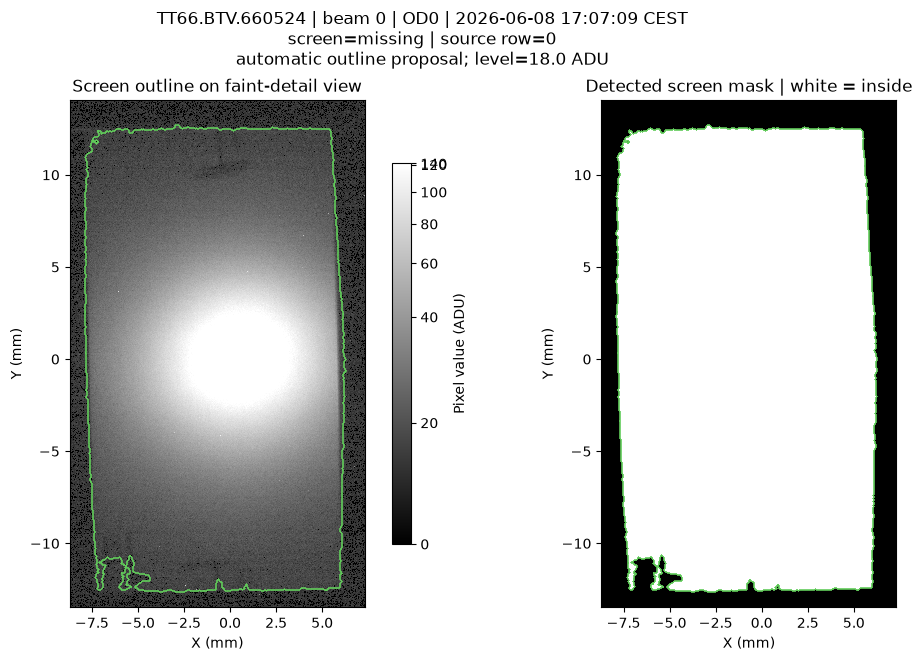

In [34]:
# Detect from raw ADU values, independently of display contrast/gamma/smoothing.
screen_mask, screen_source = screen_from_reference(raw_image)
if not screen_mask.any():
    raise ValueError("The screen mask is empty. Review the reference image or polygon.")

# Inner boundary pixels, in the same row/column order as raw_image.
screen_border_mask = screen_mask & ~binary_erosion(
    screen_mask, structure=np.ones((3, 3), dtype=bool), border_value=0,
)
screen_border_rows, screen_border_columns = np.nonzero(screen_border_mask)
screen_reference_source_row = int(selected["source_row"])
print("Screen outline:", screen_source)
print("Reference source row:", screen_reference_source_row)
print(f"Screen pixels: {screen_mask.sum():,} / {screen_mask.size:,} "
      f"({100 * screen_mask.mean():.1f}%)")


def screen_edge_segments(mask, xe, ye):
    # Exact interfaces between inside/outside pixels, including image-edge borders.
    # Use stored pixel edges rather than assuming uniformly spaced coordinates.
    vertical = np.diff(np.pad(mask.astype(np.int8), ((0, 0), (1, 1))), axis=1)
    row, edge = np.nonzero(vertical)
    v = np.stack((np.column_stack((xe[edge], ye[row])),
                  np.column_stack((xe[edge], ye[row + 1]))), axis=1)
    horizontal = np.diff(np.pad(mask.astype(np.int8), ((1, 1), (0, 0))), axis=0)
    edge, column = np.nonzero(horizontal)
    h = np.stack((np.column_stack((xe[column], ye[edge])),
                  np.column_stack((xe[column + 1], ye[edge]))), axis=1)
    return np.concatenate((v, h), axis=0)


segments = screen_edge_segments(screen_mask, x_edges, y_edges)
faint_image = display_image(DISPLAY_SMOOTHING_PIXELS)
low, high = choose_limits(faint_image, LOWER_ADU, UPPER_ADU)
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), constrained_layout=True)

artist = axes[0].pcolormesh(
    x_edges, y_edges, faint_image, shading="flat", cmap="gray", rasterized=True,
    norm=PowerNorm(GAMMA, low, high, clip=True),
)
axes[0].set_title("Screen outline on faint-detail view")
fig.colorbar(artist, ax=axes[0], label="Pixel value (ADU)", shrink=0.75)
axes[1].pcolormesh(
    x_edges, y_edges, screen_mask.astype(int), shading="flat", cmap="gray",
    vmin=0, vmax=1, rasterized=True,
)
axes[1].set_title("Detected screen mask | white = inside")

for ax in axes:
    ax.add_collection(LineCollection(segments, colors="#62cc5b", linewidths=1.2))
    ax.set_xlim(x_edges.min(), x_edges.max())
    ax.set_ylim(y_edges.min(), y_edges.max())
    if coordinate_unit == "pixel":
        ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set(xlabel=f"X ({coordinate_unit})", ylabel=f"Y ({coordinate_unit})")

fig.suptitle(image_title + "\n" + screen_source)
plt.show()
plt.close(fig)

### Using what you see

Try several beam and background frames, checking filter, screen position, image geometry,
exposure and gain. Screen-shaped edges that recur at the same stored coordinates are
worth reviewing; isolated bright pixels alone do not define the screen.
If no background frame records a boundary, a separately verified screen-visible frame
can provide a reference outline only when the screen position and camera geometry match.
Section 7 proposes an outline from the selected raw reference image. It does not automatically transfer a reference mask when you select a different frame.

**Basis:** `BTV_Image_Plotting.ipynb` (stored BTV axes and pixel-centre boundaries),
`Background_Evolution_Thesis_Figures-2 (1).ipynb` (BTV merged path and configuration),
and `Median_Background_Configuration_Study-2 (1).ipynb` (beam/no-beam definitions and the exact screen-detection functions).
The notebook needs the original `/eos/...` parquet accessible from SWAN.

**Validation:** the cell logic and plots were checked with synthetic merged-parquet
files, including both axis naming conventions and descending/nonuniform axes.
The experimental CERN parquet files were not available during creation.
The added screen functions were checked against the source notebook, and the outline
preview was exercised with synthetic screen images, including nonuniform/descending axes.
